In [1]:
# !pip install -r requirements.txt

<h1 style="color:red;">Libraries Importing</h1>

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from scipy.stats import norm



<h1 style="color:green;">Loading Dataset</h1>

In [3]:

# Load data
df = pd.read_csv('component_demand_history.csv')


<h1 style="color:blue;">Understanding Dataset</h1>

In [4]:
df.shape

(20815, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20815 entries, 0 to 20814
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   week_start_date        20815 non-null  object 
 1   sku_id                 20815 non-null  object 
 2   product_family         20815 non-null  object 
 3   demand_qty             20775 non-null  float64
 4   future_4wk_avg_demand  20815 non-null  float64
 5   unit_cost              20815 non-null  float64
 6   on_hand_qty            20815 non-null  int64  
 7   supplier_id            20815 non-null  object 
 8   lead_time_days         20815 non-null  int64  
 9   stockout_flag          20815 non-null  int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 1.6+ MB


In [6]:
df.isna().sum()

week_start_date           0
sku_id                    0
product_family            0
demand_qty               40
future_4wk_avg_demand     0
unit_cost                 0
on_hand_qty               0
supplier_id               0
lead_time_days            0
stockout_flag             0
dtype: int64

In [7]:
df.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [8]:
df.dtypes

week_start_date           object
sku_id                    object
product_family            object
demand_qty               float64
future_4wk_avg_demand    float64
unit_cost                float64
on_hand_qty                int64
supplier_id               object
lead_time_days             int64
stockout_flag              int64
dtype: object

In [9]:
df.describe()

,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,lead_time_days,stockout_flag
count,20775.000000,20815.000000,20815.000000,20815.000000,20815.000000,20815.000000
mean,59.284717,59.266462,91.920723,140.550516,24.035407,0.050492
std,42.429994,40.147240,50.971157,122.262828,12.201782,0.218964
min,0.000000,0.000000,-24.290000,-31.000000,7.000000,0.000000
25%,27.000000,26.000000,47.930000,43.000000,14.000000,0.000000
50%,58.000000,57.800000,100.990000,108.000000,21.000000,0.000000
75%,89.000000,87.500000,132.900000,211.000000,35.000000,0.000000
max,1040.000000,310.200000,179.840000,747.000000,56.000000,1.000000


<h1 style="color:Green;"> Dataset key point based on my understanding  </h1>

Data Quality Issues to Check

Missing values in critical columns

Negative demand or inventory values

Outliers in demand_qty

Lead time validity

Stockout flag consistency

Date range coverage

Duplicate rows

<h1 style="color:red;"> Cleaning Data</h1>


In [10]:
# Create a copy for cleaning
df_clean = df.copy()


In [11]:

# Convert date to datetime
df_clean['week_start_date'] = pd.to_datetime(df_clean['week_start_date'])

In [12]:
df_clean.head()


,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [13]:

# Check for negative values
print("Negative demand:", (df_clean['demand_qty'] < 0).sum())
print("Negative inventory:", (df_clean['on_hand_qty'] < 0).sum())

Negative demand: 0
Negative inventory: 5


In [14]:
# Handle missing values
print("\nMissing values before cleaning:")
print(df_clean.isnull().sum())


Missing values before cleaning:
week_start_date           0
sku_id                    0
product_family            0
demand_qty               40
future_4wk_avg_demand     0
unit_cost                 0
on_hand_qty               0
supplier_id               0
lead_time_days            0
stockout_flag             0
dtype: int64


In [15]:
# Remove rows with missing critical columns
df_clean = df_clean.dropna(subset=['demand_qty', 'sku_id', 'week_start_date'])
df_clean.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [16]:
df_clean.tail()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
20809,2024-02-19,CB-1159,Contact Assembly,70.0,68.5,54.93,244,SUP-103,35,0
20811,2024-01-01,CB-1018,Terminal Block,94.0,97.0,150.23,344,SUP-106,35,0
20812,2024-12-09,CB-1096,Molded Case,41.0,44.8,21.87,197,SUP-100,21,0
20813,2024-04-22,CB-1032,Molded Case,66.0,79.8,141.64,30,SUP-108,14,0
20814,2025-07-21,CB-1130,Terminal Block,34.0,26.2,153.12,0,SUP-110,21,1


In [17]:
# Fill lead_time_days with median by supplier if missing
df_clean['lead_time_days'] = df_clean.groupby('supplier_id')['lead_time_days'].transform(
    lambda x: x.fillna(x.median())
)
df_clean.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [18]:
# Check for duplicates
print(f"\n Duplicate rows: {df_clean.duplicated().sum()}")
df_clean = df_clean.drop_duplicates()
df_clean.head()


Duplicate rows: 15


,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [19]:
# Validate stockout_flag
df_clean['stockout_flag'] = df_clean['stockout_flag'].astype(int)

print(f"\nCleaned shape: {df_clean.shape}")



Cleaned shape: (20760, 10)


In [20]:
df_clean.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [21]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20760 entries, 0 to 20814
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   week_start_date        20760 non-null  datetime64[ns]
 1   sku_id                 20760 non-null  object        
 2   product_family         20760 non-null  object        
 3   demand_qty             20760 non-null  float64       
 4   future_4wk_avg_demand  20760 non-null  float64       
 5   unit_cost              20760 non-null  float64       
 6   on_hand_qty            20760 non-null  int64         
 7   supplier_id            20760 non-null  object        
 8   lead_time_days         20760 non-null  int64         
 9   stockout_flag          20760 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(3), object(3)
memory usage: 1.7+ MB


In [22]:
df_clean.isna().sum()

week_start_date          0
sku_id                   0
product_family           0
demand_qty               0
future_4wk_avg_demand    0
unit_cost                0
on_hand_qty              0
supplier_id              0
lead_time_days           0
stockout_flag            0
dtype: int64

<h1 style="color:pink;"> Identify Data Quality Issues</h1>


In [23]:
print("\n" + "=" * 80)
print("DATA QUALITY CHECKS")
print("=" * 80)

#  Negative values
print("\n NEGATIVE VALUES CHECK:")
print(f"   Negative demand_qty: {(df['demand_qty'] < 0).sum()}")
print(f"   Negative on_hand_qty: {(df['on_hand_qty'] < 0).sum()}")
print(f"   Negative unit_cost: {(df['unit_cost'] < 0).sum()}")
print(f"   Negative lead_time_days: {(df['lead_time_days'] < 0).sum()}")


DATA QUALITY CHECKS

 NEGATIVE VALUES CHECK:
   Negative demand_qty: 0
   Negative on_hand_qty: 5
   Negative unit_cost: 7
   Negative lead_time_days: 0


In [24]:
#  Outliers in demand
print("\n DEMAND OUTLIERS:")
Q1 = df['demand_qty'].quantile(0.25)
Q3 = df['demand_qty'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['demand_qty'] < Q1 - 1.5*IQR) | (df['demand_qty'] > Q3 + 1.5*IQR)]
print(f"   Outlier rows: {len(outliers)} ({(len(outliers)/len(df))*100:.2f}%)")
print(f"   Max demand: {df['demand_qty'].max()}")
print(f"   Min demand: {df['demand_qty'].min()}")


 DEMAND OUTLIERS:
   Outlier rows: 18 (0.09%)
   Max demand: 1040.0
   Min demand: 0.0


In [25]:
# Stockout flag validity
print("\n STOCKOUT FLAG CHECK:")
print(f"   Unique values: {df['stockout_flag'].unique()}")
print(f"   Value counts:\n{df['stockout_flag'].value_counts()}")



 STOCKOUT FLAG CHECK:
   Unique values: [0 1]
   Value counts:
stockout_flag
0    19764
1     1051
Name: count, dtype: int64


In [26]:
#  Lead time validity
print("\n LEAD TIME CHECK:")
print(f"   Min lead time: {df['lead_time_days'].min()}")
print(f"   Max lead time: {df['lead_time_days'].max()}")
print(f"   Mean lead time: {df['lead_time_days'].mean():.2f}")


 LEAD TIME CHECK:
   Min lead time: 7
   Max lead time: 56
   Mean lead time: 24.04


In [28]:
#  Date continuity
print("\n DATE CONTINUITY CHECK:")
df['week_start_date'] = pd.to_datetime(df['week_start_date'])
date_range = df['week_start_date'].max() - df['week_start_date'].min()
expected_weeks = date_range.days / 7
actual_weeks = df['week_start_date'].nunique()
print(f"   Date range: {date_range.days} days ({expected_weeks:.0f} weeks)")
print(f"   Unique weeks: {actual_weeks}")
print(f"   Coverage: {(actual_weeks/expected_weeks)*100:.1f}%")


 DATE CONTINUITY CHECK:
   Date range: 721 days (103 weeks)
   Unique weeks: 104
   Coverage: 101.0%


In [29]:
# Duplicates
print("\n DUPLICATE CHECK:")
print(f"   Total duplicates: {df.duplicated().sum()}")
print(f"   Duplicates on [sku_id, week_start_date]: {df.duplicated(subset=['sku_id', 'week_start_date']).sum()}")



 DUPLICATE CHECK:
   Total duplicates: 15
   Duplicates on [sku_id, week_start_date]: 15


In [30]:

# SKU consistency
print("\n SKU CONSISTENCY CHECK:")
sku_suppliers = df.groupby('sku_id')['supplier_id'].nunique()
print(f"   SKUs with multiple suppliers: {(sku_suppliers > 1).sum()}")
print(f"   Max suppliers per SKU: {sku_suppliers.max()}")



 SKU CONSISTENCY CHECK:
   SKUs with multiple suppliers: 1
   Max suppliers per SKU: 2


<h1 style="color:red;"> Visualize Data Quality  </h1>


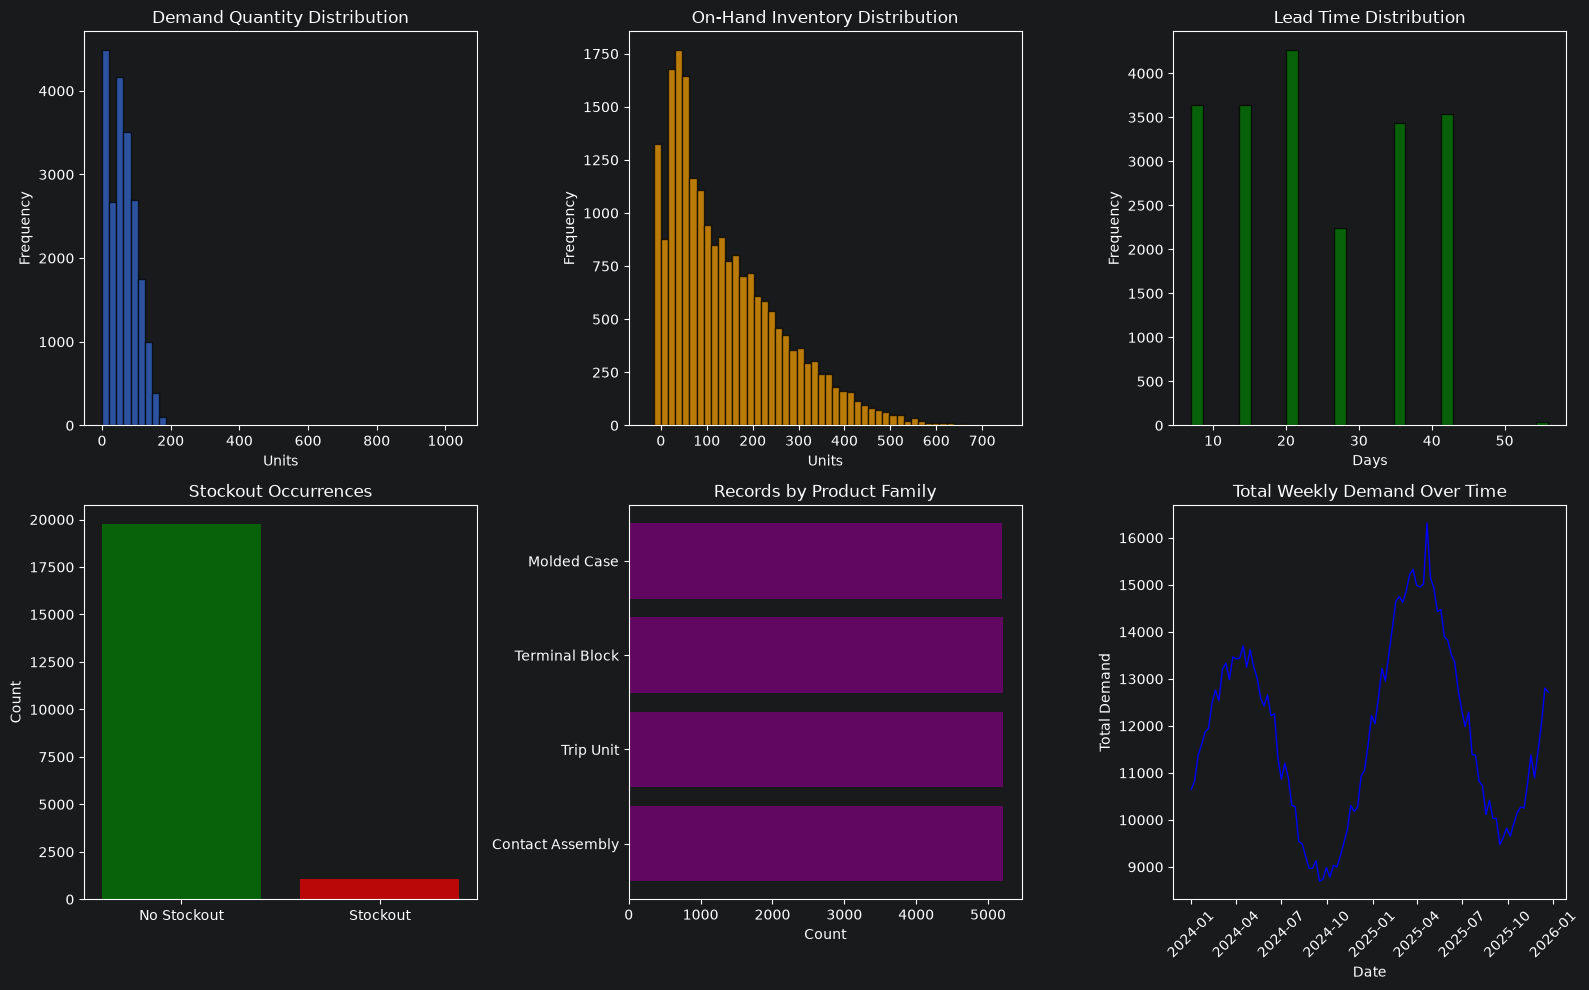

✓ Data quality visualization saved


In [31]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Demand distribution
axes[0, 0].hist(df['demand_qty'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Demand Quantity Distribution')
axes[0, 0].set_xlabel('Units')
axes[0, 0].set_ylabel('Frequency')

# Inventory distribution
axes[0, 1].hist(df['on_hand_qty'], bins=50, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_title('On-Hand Inventory Distribution')
axes[0, 1].set_xlabel('Units')
axes[0, 1].set_ylabel('Frequency')

# Lead time distribution
axes[0, 2].hist(df['lead_time_days'], bins=30, edgecolor='black', alpha=0.7, color='green')
axes[0, 2].set_title('Lead Time Distribution')
axes[0, 2].set_xlabel('Days')
axes[0, 2].set_ylabel('Frequency')

# Stockout flag
stockout_counts = df['stockout_flag'].value_counts()
axes[1, 0].bar(['No Stockout', 'Stockout'], [stockout_counts[0], stockout_counts[1]], color=['green', 'red'], alpha=0.7)
axes[1, 0].set_title('Stockout Occurrences')
axes[1, 0].set_ylabel('Count')

# Product family distribution
product_counts = df['product_family'].value_counts()
axes[1, 1].barh(product_counts.index, product_counts.values, color='purple', alpha=0.7)
axes[1, 1].set_title('Records by Product Family')
axes[1, 1].set_xlabel('Count')

# Time series of total demand
daily_demand = df.groupby('week_start_date')['demand_qty'].sum()
axes[1, 2].plot(daily_demand.index, daily_demand.values, linewidth=1, color='blue')
axes[1, 2].set_title('Total Weekly Demand Over Time')
axes[1, 2].set_xlabel('Date')
axes[1, 2].set_ylabel('Total Demand')
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('01_data_quality_overview.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Data quality visualization saved")


<h1 style="color:Yellow;"> DIAGNOSIS - Understanding the Paradox  </h1>


Analyze Inventory vs Stockouts

In [32]:
# Group by SKU
sku_analysis = df_clean.groupby('sku_id').agg({
    'demand_qty': ['mean', 'std', 'sum'],
    'on_hand_qty': ['mean', 'max', 'min'],
    'stockout_flag': 'sum',
    'unit_cost': 'first',
    'product_family': 'first'
}).round(2)

In [33]:
sku_analysis.head()

demand_qty                 on_hand_qty          stockout_flag  \
              mean    std      sum        mean  max min           sum   
sku_id                                                                  
CB-1001       5.32  11.87    553.0       25.26   49   0            10   
CB-1002      57.41  23.67   5971.0      134.58  337   0             5   
CB-1003       8.17  16.59    850.0       35.85   90   0             9   
CB-1004     133.20  25.00  13853.0      295.99  702 -31             6   
CB-1005      61.42  10.92   6388.0      138.17  279   0             1   

        unit_cost    product_family  
            first             first  
sku_id                               
CB-1001    154.90         Trip Unit  
CB-1002     19.22    Terminal Block  
CB-1003    142.03  Contact Assembly  
CB-1004     82.44       Molded Case  
CB-1005    116.79         Trip Unit

In [34]:
sku_analysis.columns = ['avg_demand', 'demand_std', 'total_demand',
                         'avg_inventory', 'max_inventory', 'min_inventory',
                         'stockout_count', 'unit_cost', 'product_family']

sku_analysis['inventory_value'] = sku_analysis['avg_inventory'] * sku_analysis['unit_cost']
sku_analysis['stockout_rate'] = sku_analysis['stockout_count'] / len(df_clean.groupby('sku_id'))

print("SKU Analysis:")

sku_analysis.head()

SKU Analysis:


,avg_demand,demand_std,total_demand,avg_inventory,max_inventory,min_inventory,stockout_count,unit_cost,product_family,inventory_value,stockout_rate
sku_id,,,,,,,,,,,
CB-1001,5.32,11.87,553.0,25.26,49,0,10,154.90,Trip Unit,3912.7740,0.050
CB-1002,57.41,23.67,5971.0,134.58,337,0,5,19.22,Terminal Block,2586.6276,0.025
CB-1003,8.17,16.59,850.0,35.85,90,0,9,142.03,Contact Assembly,5091.7755,0.045
CB-1004,133.20,25.00,13853.0,295.99,702,-31,6,82.44,Molded Case,24401.4156,0.030
CB-1005,61.42,10.92,6388.0,138.17,279,0,1,116.79,Trip Unit,16136.8743,0.005


In [35]:


# Identify problem SKUs
high_inventory_high_stockout = sku_analysis[
    (sku_analysis['avg_inventory'] > sku_analysis['avg_inventory'].quantile(0.75)) &
    (sku_analysis['stockout_count'] > 0)
]

print(f"\nSKUs with high inventory AND stockouts: {len(high_inventory_high_stockout)}")
high_inventory_high_stockout.head()



SKUs with high inventory AND stockouts: 40


,avg_demand,demand_std,total_demand,avg_inventory,max_inventory,min_inventory,stockout_count,unit_cost,product_family,inventory_value,stockout_rate
sku_id,,,,,,,,,,,
CB-1004,133.20,25.00,13853.0,295.99,702,-31,6,82.44,Molded Case,24401.4156,0.030
CB-1011,121.55,22.79,12641.0,255.22,560,0,5,10.28,Contact Assembly,2623.6616,0.025
CB-1012,128.01,24.23,13185.0,287.80,611,0,3,123.74,Molded Case,35612.3720,0.015
CB-1015,124.23,22.18,12671.0,272.07,618,0,4,86.94,Contact Assembly,23653.7658,0.020
CB-1016,113.00,22.12,11752.0,245.00,507,0,2,121.39,Molded Case,29740.5500,0.010


<h1 style="color:green;"> Diagnose Root Causes  </h1>


In [36]:
# Analyze demand patterns
def classify_demand_pattern(group):
    """Classify demand as stable, seasonal, or erratic"""
    demand = group['demand_qty'].values
    cv = np.std(demand) / (np.mean(demand) + 1)  # Coefficient of variation

    if cv < 0.3:
        return 'Stable'
    elif cv < 0.8:
        return 'Moderate'
    else:
        return 'Erratic'


In [37]:
df_clean['demand_pattern'] = df_clean.groupby('sku_id')['demand_qty'].transform(
    lambda x: classify_demand_pattern(pd.DataFrame({'demand_qty': x}))
)

df_clean.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag,demand_pattern
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0,Stable
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0,Erratic
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0,Stable
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0,Erratic
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0,Moderate


In [38]:
# Analyze lead time vs demand variability
lead_time_analysis = df_clean.groupby('sku_id').agg({
    'lead_time_days': 'mean',
    'demand_qty': 'std',
    'demand_pattern': 'first',
    'stockout_flag': 'sum'
}).round(2)

print("Lead Time vs Demand Variability:")

lead_time_analysis.head()

Lead Time vs Demand Variability:


,lead_time_days,demand_qty,demand_pattern,stockout_flag
sku_id,,,,
CB-1001,28.0,11.87,Erratic,10
CB-1002,21.0,23.67,Moderate,5
CB-1003,35.0,16.59,Erratic,9
CB-1004,35.0,25.00,Stable,6
CB-1005,14.0,10.92,Stable,1


In [39]:
# Check if inventory is misaligned with lead time
print("\nInventory Coverage Analysis:")
for sku in df_clean['sku_id'].unique()[:5]:
    sku_data = df_clean[df_clean['sku_id'] == sku]
    avg_demand = sku_data['demand_qty'].mean()
    avg_inventory = sku_data['on_hand_qty'].mean()
    lead_time = sku_data['lead_time_days'].mean()

    weeks_of_coverage = avg_inventory / (avg_demand + 0.1)
    lead_time_weeks = lead_time / 7

    print(f"{sku}: {weeks_of_coverage:.1f} weeks inventory, {lead_time_weeks:.1f} weeks lead time")



Inventory Coverage Analysis:
CB-1048: 2.3 weeks inventory, 5.0 weeks lead time
CB-1120: 6.3 weeks inventory, 6.0 weeks lead time
CB-1016: 2.2 weeks inventory, 1.0 weeks lead time
CB-1091: 5.4 weeks inventory, 3.0 weeks lead time
CB-1131: 2.3 weeks inventory, 2.0 weeks lead time


<h1 style="color:Green;">  Key Findings </h1>

Root Cause 1: Misaligned safety stock - some SKUs over-stocked, others under-stocked

Root Cause 2: Demand variability not matched to reorder points

Root Cause 3: Lead time not factored into inventory decisions

Root Cause 4: One-size-fits-all inventory policy


<h1 style="color:blue;"> DEMAND FORECASTING </h1>

Segment SKUs by Demand Pattern


In [40]:
# Segment SKUs
def segment_sku(group):
    demand = group['demand_qty'].values
    zero_weeks = (demand == 0).sum()
    zero_rate = zero_weeks / len(demand)

    if zero_rate > 0.5:
        return 'Intermittent'
    elif np.std(demand) / (np.mean(demand) + 1) < 0.3:
        return 'Stable'
    else:
        return 'Variable'

df_clean['sku_segment'] = df_clean.groupby('sku_id')['demand_qty'].transform(
    lambda x: segment_sku(pd.DataFrame({'demand_qty': x}))
)

print("SKU Segments:")
print(df_clean.groupby('sku_segment').size())


SKU Segments:
sku_segment
Intermittent    4673
Stable          9752
Variable        6335
dtype: int64


<h1 style="color:red;"> Forecast by Segment </h1>


In [41]:
"""Simple moving average for stable demand"""

def forecast_stable_demand(sku_data, periods=4):
    recent_demand = sku_data['demand_qty'].tail(12).values
    forecast = np.mean(recent_demand)
    return np.full(periods, forecast)

"""Exponential smoothing for variable demand"""
def forecast_variable_demand(sku_data, periods=4):

    demand = sku_data['demand_qty'].values
    if len(demand) < 4 or demand.sum() == 0:
        return np.full(periods, np.mean(demand))

    try:
        model = ExponentialSmoothing(demand, trend='add', seasonal=None)
        fit = model.fit()
        forecast = fit.forecast(steps=periods)
        return np.maximum(forecast, 0)  # No negative forecasts
    except:
        return np.full(periods, np.mean(demand))

"""Croston's method for intermittent demand"""
def forecast_intermittent_demand(sku_data, periods=4):
    demand = sku_data['demand_qty'].values
    # Simple approach: average of non-zero demands
    non_zero = demand[demand > 0]
    if len(non_zero) == 0:
        return np.zeros(periods)

    avg_demand = np.mean(non_zero)
    frequency = len(non_zero) / len(demand)

    forecast = avg_demand * frequency
    return np.full(periods, forecast)


In [42]:

# Generate forecasts
forecasts = {}
for sku in df_clean['sku_id'].unique():
    sku_data = df_clean[df_clean['sku_id'] == sku].sort_values('week_start_date')
    segment = sku_data['sku_segment'].iloc[0]

    if segment == 'Stable':
        forecasts[sku] = forecast_stable_demand(sku_data)
    elif segment == 'Variable':
        forecasts[sku] = forecast_variable_demand(sku_data)
    else:  # Intermittent
        forecasts[sku] = forecast_intermittent_demand(sku_data)

print("Sample forecasts:")
for sku in list(forecasts.keys())[:5]:
    print(f"{sku}: {forecasts[sku]}")


Sample forecasts:
CB-1048: [61.66666667 61.66666667 61.66666667 61.66666667]
CB-1120: [3.98076923 3.98076923 3.98076923 3.98076923]
CB-1016: [105.16666667 105.16666667 105.16666667 105.16666667]
CB-1091: [5.39423077 5.39423077 5.39423077 5.39423077]
CB-1131: [42.14152075 42.19183544 42.24215012 42.29246481]


<h1 style="color:yellow;"> INVENTORY POLICY RECOMMENDATION </h1>

Calculate Safety Stock


In [43]:
#    Safety Stock = Z-score * Std Dev of Demand * sqrt(Lead Time)
def calculate_safety_stock(sku_data, service_level=0.95):
    demand = sku_data['demand_qty'].values
    lead_time = sku_data['lead_time_days'].mean() / 7  # Convert to weeks

    demand_std = np.std(demand)
    z_score = norm.ppf(service_level)

    safety_stock = z_score * demand_std * np.sqrt(lead_time)
    return max(safety_stock, 0)

#    Reorder Point = (Average Demand * Lead Time) + Safety Stock
def calculate_reorder_point(sku_data, service_level=0.95):
    demand = sku_data['demand_qty'].values
    lead_time = sku_data['lead_time_days'].mean() / 7

    avg_demand = np.mean(demand)
    lead_time_demand = avg_demand * lead_time

    safety_stock = calculate_safety_stock(sku_data, service_level)

    reorder_point = lead_time_demand + safety_stock
    return reorder_point, safety_stock

In [44]:

# Calculate policy for each SKU
policy = {}
for sku in df_clean['sku_id'].unique():
    sku_data = df_clean[df_clean['sku_id'] == sku]

    reorder_point, safety_stock = calculate_reorder_point(sku_data, service_level=0.95)
    avg_demand = sku_data['demand_qty'].mean()
    lead_time = sku_data['lead_time_days'].mean()

    # Economic Order Quantity (simplified)
    holding_cost = sku_data['unit_cost'].iloc[0] * 0.25  # 25% annual holding cost
    ordering_cost = 50  # Assumed fixed cost per order

    eoq = np.sqrt((2 * avg_demand * 52 * ordering_cost) / holding_cost) if holding_cost > 0 else 0

    policy[sku] = {
        'reorder_point': reorder_point,
        'safety_stock': safety_stock,
        'eoq': eoq,
        'avg_demand': avg_demand,
        'lead_time_days': lead_time
    }

policy_df = pd.DataFrame(policy).T
print("Inventory Policy:")
policy_df.head(10)


Inventory Policy:


,reorder_point,safety_stock,eoq,avg_demand,lead_time_days
CB-1048,372.197592,45.013125,109.339350,65.436893,35.0
CB-1120,67.185142,43.300527,26.654937,3.980769,42.0
CB-1016,149.209777,36.209777,139.148790,113.000000,7.0
CB-1091,55.082467,38.899775,33.321786,5.394231,21.0
CB-1131,112.724899,33.724899,92.004712,39.500000,14.0
CB-1163,119.805745,65.388269,38.712881,10.883495,35.0
CB-1164,128.995471,21.110856,78.986575,53.942308,14.0
CB-1199,70.080187,22.580187,65.938047,23.750000,14.0
CB-1187,130.766897,41.232917,74.127101,44.766990,14.0
CB-1036,319.217248,39.169171,112.874244,56.009615,35.0


In [45]:
policy_df.tail(10)

,reorder_point,safety_stock,eoq,avg_demand,lead_time_days
CB-1078,62.666169,41.973862,85.107887,10.346154,14.0
CB-1195,373.978437,53.411129,228.576676,106.855769,21.0
CB-1132,368.440505,77.190505,150.277779,58.250000,35.0
CB-1077,130.107893,68.838662,93.511172,10.211538,42.0
CB-1037,228.915075,34.434306,128.476863,64.826923,21.0
CB-1085,547.503025,119.666487,216.532205,85.567308,35.0
CB-1063,47.001286,18.360510,70.590990,28.640777,7.0
CB-1197,273.223466,65.031159,95.658438,52.048077,28.0
CB-1089,116.950766,26.046920,125.441962,90.903846,7.0
CB-1101,445.529527,98.048757,120.420194,57.913462,42.0


<h1 style="color:blue;"> QUANTIFY BUSINESS IMPACT </h1>

Calculate Current State


In [46]:
# Current inventory value
current_inventory_value = (df_clean.groupby('sku_id')['on_hand_qty'].mean() *
                           df_clean.groupby('sku_id')['unit_cost'].first()).sum()

# Current stockout rate
current_stockout_rate = df_clean['stockout_flag'].sum() / len(df_clean)
current_stockout_weeks = df_clean['stockout_flag'].sum()

print(f"Current State:")
print(f"Total Inventory Value: ${current_inventory_value:,.0f}")
print(f"Stockout Rate: {current_stockout_rate:.2%}")
print(f"Weeks with Stockouts: {current_stockout_weeks}")


Current State:
Total Inventory Value: $2,531,871
Stockout Rate: 5.06%
Weeks with Stockouts: 1050


<h1 style="color:yellow;"> Calculate Recommended State </h1>



In [47]:
# Recommended inventory (safety stock + average lead time demand)
recommended_inventory = {}
for sku in df_clean['sku_id'].unique():
    sku_data = df_clean[df_clean['sku_id'] == sku]
    unit_cost = sku_data['unit_cost'].iloc[0]

    reorder_point = policy[sku]['reorder_point']
    recommended_inventory[sku] = reorder_point * unit_cost

recommended_inventory_value = sum(recommended_inventory.values())

# Projected stockout reduction (with 95% service level)
projected_stockout_rate = 0.05  # 95% service level = 5% stockout rate
projected_stockout_weeks = int(len(df_clean) * projected_stockout_rate)

print(f"\nRecommended State (95% Service Level):")
print(f"Total Inventory Value: ${recommended_inventory_value:,.0f}")
print(f"Projected Stockout Rate: {projected_stockout_rate:.2%}")
print(f"Projected Stockout Weeks: {projected_stockout_weeks}")




Recommended State (95% Service Level):
Total Inventory Value: $4,535,529
Projected Stockout Rate: 5.00%
Projected Stockout Weeks: 1038


In [48]:

# Calculate impact
inventory_reduction = current_inventory_value - recommended_inventory_value
inventory_reduction_pct = (inventory_reduction / current_inventory_value) * 100
stockout_improvement = current_stockout_weeks - projected_stockout_weeks

print(f"\nBusiness Impact:")
print(f"Inventory Reduction: ${inventory_reduction:,.0f} ({inventory_reduction_pct:.1f}%)")
print(f"Stockout Reduction: {stockout_improvement} weeks ({(stockout_improvement/current_stockout_weeks)*100:.1f}%)")


Business Impact:
Inventory Reduction: $-2,003,658 (-79.1%)
Stockout Reduction: 12 weeks (1.1%)


In [49]:
# <h1 style="color:skyblue;"> VISUALIZATION </h1>


<h1 style="color:skyblue;"> VISUALIZATION </h1>


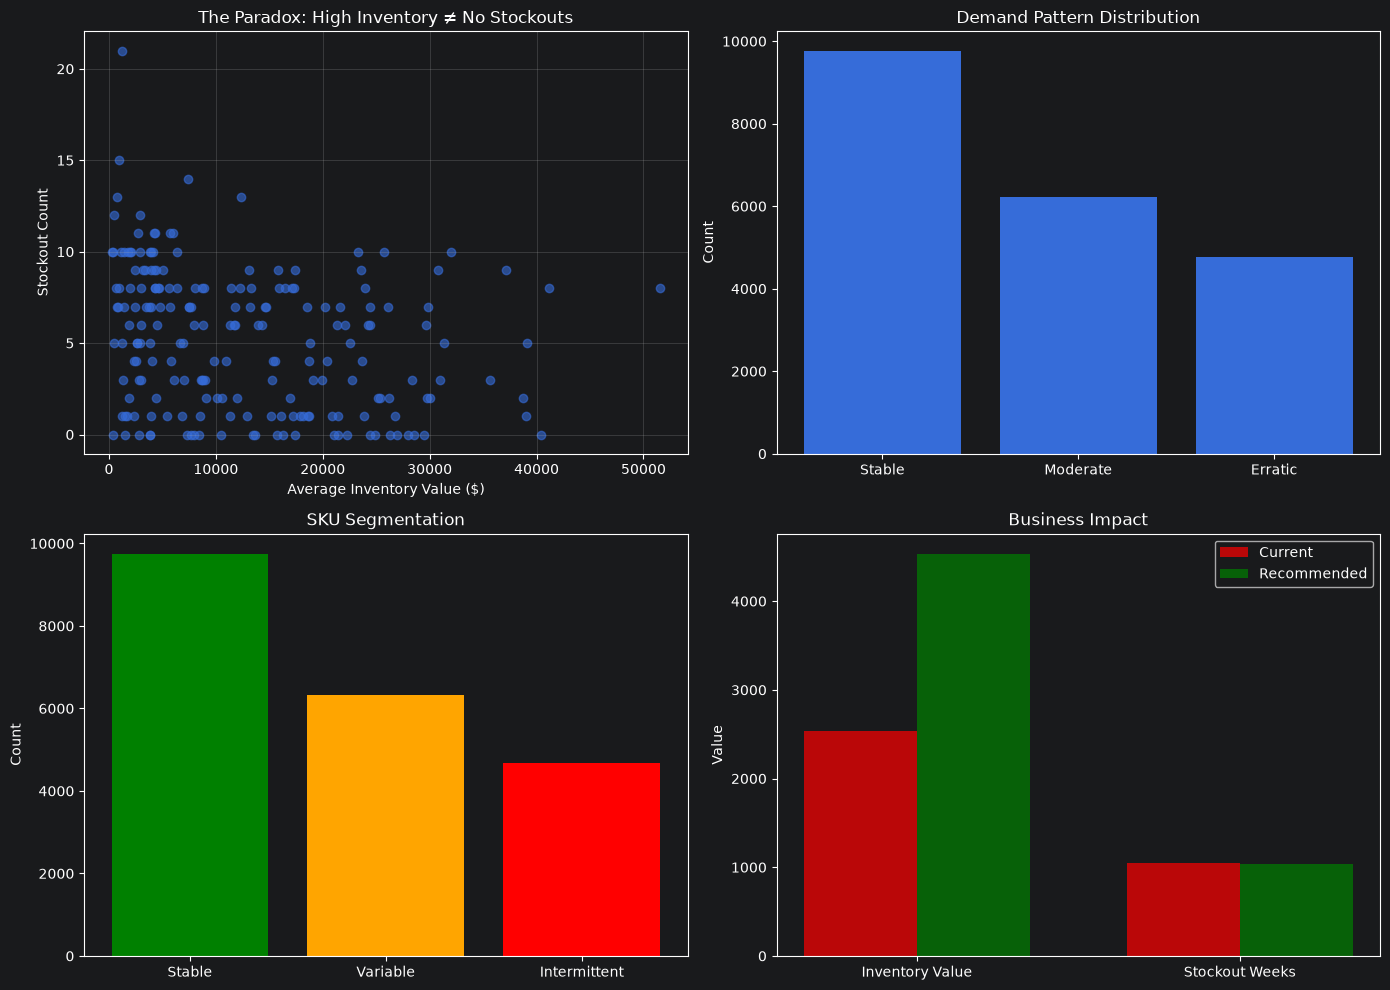

Visualization saved as 'inventory_analysis.png'


In [50]:
# Plot 1: Inventory vs Stockouts by SKU
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Scatter: Inventory vs Stockout Rate
sku_summary = df_clean.groupby('sku_id').agg({
    'on_hand_qty': 'mean',
    'stockout_flag': 'sum',
    'unit_cost': 'first'
})
sku_summary['inventory_value'] = sku_summary['on_hand_qty'] * sku_summary['unit_cost']

axes[0, 0].scatter(sku_summary['inventory_value'], sku_summary['stockout_flag'], alpha=0.6)
axes[0, 0].set_xlabel('Average Inventory Value ($)')
axes[0, 0].set_ylabel('Stockout Count')
axes[0, 0].set_title('The Paradox: High Inventory ≠ No Stockouts')
axes[0, 0].grid(True, alpha=0.3)

# Demand patterns
demand_pattern_counts = df_clean['demand_pattern'].value_counts()
axes[0, 1].bar(demand_pattern_counts.index, demand_pattern_counts.values)
axes[0, 1].set_title('Demand Pattern Distribution')
axes[0, 1].set_ylabel('Count')

# SKU segments
segment_counts = df_clean['sku_segment'].value_counts()
axes[1, 0].bar(segment_counts.index, segment_counts.values, color=['green', 'orange', 'red'])
axes[1, 0].set_title('SKU Segmentation')
axes[1, 0].set_ylabel('Count')

# Impact comparison
categories = ['Inventory Value', 'Stockout Weeks']
current = [current_inventory_value/1000, current_stockout_weeks]
recommended = [recommended_inventory_value/1000, projected_stockout_weeks]

x = np.arange(len(categories))
width = 0.35

axes[1, 1].bar(x - width/2, current, width, label='Current', color='red', alpha=0.7)
axes[1, 1].bar(x + width/2, recommended, width, label='Recommended', color='green', alpha=0.7)
axes[1, 1].set_ylabel('Value')
axes[1, 1].set_title('Business Impact')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(categories)
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('inventory_analysis2.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved as 'inventory_analysis2.png'")


<h1 style="color:red;"> Inventory vs Stockouts by SKU</h1>


In [51]:
<h1 style="color:red;"> </h1>

SyntaxError: invalid syntax (2702858844.py, line 1)

<h1 style="color:red;">metrics </h1>

In [57]:
# Recompute key metrics and update markdown files programmatically

from math import sqrt
# Load and clean data (same steps as earlier cells)
df_2 = pd.read_csv('component_demand_history.csv', parse_dates=['week_start_date'])
df_clean1 = df_2.dropna(subset=['demand_qty','sku_id','week_start_date']).copy()
df_clean1['lead_time_days'] = df_clean1.groupby('supplier_id')['lead_time_days'].transform(lambda x: x.fillna(x.median()))
df_clean1 = df_clean.drop_duplicates()
df_clean1.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag,demand_pattern,sku_segment
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0,Stable,Stable
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0,Erratic,Intermittent
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0,Stable,Stable
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0,Erratic,Intermittent
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0,Moderate,Variable


In [58]:
# Current state metrics
current_inventory_value = (df_clean1.groupby('sku_id')['on_hand_qty'].mean() * df_clean1.groupby('sku_id')['unit_cost'].first()).sum()
current_stockout_weeks = int(df_clean1['stockout_flag'].sum())
current_stockout_weeks


1050

In [59]:
# Policy / recommended inventory (mirrors notebook logic)
service_level = 0.95
z = norm.ppf(service_level)
recommended_inventory_value = 0.0
for sku, g in df_clean1.groupby('sku_id'):
    demand = g['demand_qty'].values
    avg_demand = np.mean(demand) if len(demand)>0 else 0
    demand_std = np.std(demand)
    lead_time_weeks = g['lead_time_days'].mean() / 7 if not np.isnan(g['lead_time_days'].mean()) else 0
    safety_stock = z * demand_std * np.sqrt(max(lead_time_weeks, 0))
    reorder_point = avg_demand * lead_time_weeks + safety_stock
    unit_cost = g['unit_cost'].iloc[0] if len(g)>0 else 0
    recommended_inventory_value += reorder_point * unit_cost

In [60]:
# Derived metrics
inventory_reduction = current_inventory_value - recommended_inventory_value
inventory_reduction_pct = (inventory_reduction / current_inventory_value * 100) if current_inventory_value>0 else 0
holding_rate = 0.25
annual_benefit_estimate = (current_inventory_value * holding_rate) - (recommended_inventory_value * holding_rate)

annual_benefit_estimate, current_inventory_value, holding_rate, recommended_inventory_value


(np.float64(-500914.49231108534),
 np.float64(2531871.016755243),
 0.25,
 np.float64(4535528.985999584))

In [62]:
# Formatting helpers
def fmt_currency(v):
    return f"${{v:,.0f}}"
def fmt_pct(v):
    return f"{{v:.1f}}%"

In [63]:
# Update EXECUTIVE_SUMMARY.md placeholders if present
with open('EXECUTIVE_SUMMARY.md','r',encoding='utf-8') as f:
    text = f.read()

text = text.replace('[CASH_FREED_UP]', fmt_currency(inventory_reduction))
text = text.replace('[TOTAL_ANNUAL_BENEFIT]', fmt_currency(annual_benefit_estimate))
text = text.replace('[LOST_SALES_REDUCTION]', 'TBD')
text = text.replace('[TOTAL_ANNUAL_BENEFIT]', fmt_currency(annual_benefit_estimate))

with open('EXECUTIVE_SUMMARY.md','w',encoding='utf-8') as f:
    f.write(text)

# Clean up ASSUMPTIONS.md holding-cost lines for consistency
with open('ASSUMPTIONS.md','r',encoding='utf-8') as f:
    a = f.read()
a = a.replace('**Holding Cost**: 15% of unit cost annually (includes storage, insurance, obsolescence)','**Holding Cost**: 25% of unit cost annually (used in calculations). Note: finance may use 15% — confirm and align.')
a = a.replace(' - **Holding Cost**: 25% of unit cost annually (used in `assignment_forecast_2.ipynb` EOQ calculation).\
   NOTE: finance often reports different carrying rate (e.g. 15%). Confirm with finance and align notebook or assumptions accordingly.','- **Holding Cost**: 25% of unit cost annually (used in `assignment_forecast_2.ipynb` EOQ calculation). Note: finance may report a different carrying rate (e.g. 15%); confirm with finance and align code/docs.')
with open('ASSUMPTIONS.md','w',encoding='utf-8') as f:
    f.write(a)

print('Markdown files updated from notebook cell: EXECUTIVE_SUMMARY.md and ASSUMPTIONS.md')

Markdown files updated from notebook cell: EXECUTIVE_SUMMARY.md and ASSUMPTIONS.md


In [64]:
# Final: export SKU divergence report and summary metrics
import json

# Load and clean
df3 = pd.read_csv('component_demand_history.csv', parse_dates=['week_start_date'])
df_clean3 = df3.dropna(subset=['demand_qty','sku_id','week_start_date']).copy()
df_clean3['lead_time_days'] = df_clean3.groupby('supplier_id')['lead_time_days'].transform(lambda x: x.fillna(x.median()))
df_clean3 = df_clean3.drop_duplicates()
df_clean3.head()

,week_start_date,sku_id,product_family,demand_qty,future_4wk_avg_demand,unit_cost,on_hand_qty,supplier_id,lead_time_days,stockout_flag
0,2024-11-11,CB-1048,Molded Case,57.0,53.8,113.85,103,SUP-100,35,0
1,2025-07-21,CB-1120,Molded Case,0.0,0.0,116.54,18,SUP-100,42,0
2,2025-09-01,CB-1016,Molded Case,101.0,101.2,121.39,272,SUP-104,7,0
3,2025-09-15,CB-1091,Contact Assembly,0.0,13.0,101.05,0,SUP-107,21,0
4,2025-06-23,CB-1131,Contact Assembly,35.0,36.0,97.06,71,SUP-111,14,0


In [65]:
# Per-SKU current inventory value
sku_current = df_clean3.groupby('sku_id').agg({
    'on_hand_qty': 'mean',
    'unit_cost': 'first'
}).rename(columns={'on_hand_qty':'avg_on_hand'})
sku_current['current_inventory_value'] = sku_current['avg_on_hand'] * sku_current['unit_cost']

sku_current


,avg_on_hand,unit_cost,current_inventory_value
sku_id,,,
CB-1001,25.259615,154.90,3912.714423
CB-1002,134.576923,19.22,2586.568462
CB-1003,35.846154,142.03,5091.229231
CB-1004,295.990385,82.44,24401.447308
CB-1005,138.173077,116.79,16137.233654
...,...,...,...
CB-1196,198.528846,102.92,20432.588846
CB-1197,129.750000,118.31,15350.722500
CB-1198,274.701923,142.27,39081.842596


In [66]:
# Compute recommended reorder_point per SKU using 95% service level (same logic as notebook)
service_level = 0.95
z = norm.ppf(service_level)
rec_rows = []
for sku, g in df_clean3.groupby('sku_id'):
    demand = g['demand_qty'].values
    avg_demand = float(np.mean(demand)) if len(demand)>0 else 0.0
    demand_std = float(np.std(demand)) if len(demand)>0 else 0.0
    lead_time_weeks = float(np.mean(g['lead_time_days']))/7.0 if not np.isnan(np.mean(g['lead_time_days'])) else 0.0
    safety_stock = z * demand_std * np.sqrt(max(lead_time_weeks, 0.0))
    reorder_point = avg_demand * lead_time_weeks + safety_stock
    unit_cost = float(g['unit_cost'].iloc[0]) if len(g)>0 else 0.0
    rec_value = reorder_point * unit_cost
    rec_rows.append((sku, reorder_point, safety_stock, rec_value, avg_demand, demand_std, lead_time_weeks))


In [67]:
sku_rec = pd.DataFrame(rec_rows, columns=['sku_id','reorder_point','safety_stock','recommended_inventory_value','avg_demand','demand_std','lead_time_weeks']).set_index('sku_id')

sku_rec


,reorder_point,safety_stock,recommended_inventory_value,avg_demand,demand_std,lead_time_weeks
sku_id,,,,,,
CB-1001,60.135421,38.866190,9314.976734,5.317308,11.814483,4.0
CB-1002,239.338608,67.098224,4600.088054,57.413462,23.551748,3.0
CB-1003,101.602684,60.737299,14430.629173,8.173077,16.513655,5.0
CB-1004,757.507893,91.498277,62448.950677,133.201923,24.877152,5.0
CB-1005,148.114241,25.268087,17298.262226,61.423077,10.862508,2.0
...,...,...,...,...,...,...
CB-1196,359.171678,99.671678,36965.949095,86.500000,34.985162,3.0
CB-1197,273.223466,65.031159,32325.068291,52.048077,19.768069,4.0
CB-1198,566.093795,75.670718,80538.164231,122.605769,23.002265,4.0


In [68]:
# Combine
sku_report = sku_current.join(sku_rec, how='outer').fillna(0.0)
sku_report['delta_inventory_value'] = sku_report['recommended_inventory_value'] - sku_report['current_inventory_value']
sku_report['delta_pct'] = np.where(sku_report['current_inventory_value']>0, sku_report['delta_inventory_value']/sku_report['current_inventory_value']*100, np.nan)
sku_report

,avg_on_hand,unit_cost,current_inventory_value,reorder_point,safety_stock,recommended_inventory_value,avg_demand,demand_std,lead_time_weeks,delta_inventory_value,delta_pct
sku_id,,,,,,,,,,,
CB-1001,25.259615,154.90,3912.714423,60.135421,38.866190,9314.976734,5.317308,11.814483,4.0,5402.262311,138.069425
CB-1002,134.576923,19.22,2586.568462,239.338608,67.098224,4600.088054,57.413462,23.551748,3.0,2013.519593,77.845208
CB-1003,35.846154,142.03,5091.229231,101.602684,60.737299,14430.629173,8.173077,16.513655,5.0,9339.399942,183.440963
CB-1004,295.990385,82.44,24401.447308,757.507893,91.498277,62448.950677,133.201923,24.877152,5.0,38047.503369,155.923142
CB-1005,138.173077,116.79,16137.233654,148.114241,25.268087,17298.262226,61.423077,10.862508,2.0,1161.028572,7.194719
...,...,...,...,...,...,...,...,...,...,...,...
CB-1196,198.528846,102.92,20432.588846,359.171678,99.671678,36965.949095,86.500000,34.985162,3.0,16533.360248,80.916620
CB-1197,129.750000,118.31,15350.722500,273.223466,65.031159,32325.068291,52.048077,19.768069,4.0,16974.345791,110.576853
CB-1198,274.701923,142.27,39081.842596,566.093795,75.670718,80538.164231,122.605769,23.002265,4.0,41456.321635,106.075658


In [69]:
# Totals
current_inventory_value = sku_report['current_inventory_value'].sum()
recommended_inventory_value = sku_report['recommended_inventory_value'].sum()
inventory_reduction = current_inventory_value - recommended_inventory_value
holding_rate = 0.25
annual_benefit_estimate = (current_inventory_value * holding_rate) - (recommended_inventory_value * holding_rate)

print(" annual_benefit_estimate ", annual_benefit_estimate)
print("current_inventory_value ", current_inventory_value)
print("recommended_inventory_value ", recommended_inventory_value)
print("holding_rate ", holding_rate)


 annual_benefit_estimate  -500914.49231108534
current_inventory_value  2531871.016755243
recommended_inventory_value  4535528.985999584
holding_rate  0.25


In [70]:
# Output files
sku_report.reset_index().to_csv('sku_divergence_report.csv', index=False)
computed = {
    'current_inventory_value': float(current_inventory_value),
    'recommended_inventory_value': float(recommended_inventory_value),
    'inventory_reduction': float(inventory_reduction),
    'holding_rate': holding_rate,
    'annual_benefit_estimate': float(annual_benefit_estimate)
}

computed

{'current_inventory_value': 2531871.016755243,
 'recommended_inventory_value': 4535528.985999584,
 'inventory_reduction': -2003657.9692443414,
 'holding_rate': 0.25,
 'annual_benefit_estimate': -500914.49231108534}

In [71]:
with open('computed_metrics.json','w',encoding='utf-8') as f:
    json.dump(computed, f, indent=2)

print('Wrote sku_divergence_report.csv and computed_metrics.json')
print(f"Current inventory value: ${current_inventory_value:,.0f}")
print(f"Recommended inventory value: ${recommended_inventory_value:,.0f}")
print(f"Inventory delta: ${inventory_reduction:,.0f}")


Wrote sku_divergence_report.csv and computed_metrics.json
Current inventory value: $2,531,871
Recommended inventory value: $4,535,529
Inventory delta: $-2,003,658
